# Praemonitus - machine failure prediction

Course project for *Artificial Intelligence Systems*. The notebook follows the
project stages: problem, data, data quality, exploratory analysis, models,
threshold and model choice, test and error analysis, explainability.

All logic lives in the `ml/` package; the notebook calls it and shows the
results. `python -m ml.train` reproduces the saved model with the same code.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from ml import data as D
from ml import evaluate as E
from ml import train as T
from ml.features import compute_derived

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Problem

Given the parameters of one machining run - product variant, air and process
temperature, rotational speed, torque and tool wear - predict whether the run
ends with a machine failure.

* **Task:** binary classification, target `Machine failure` (0/1).
* **Observation:** one process run with its parameters and label.
* **User of the result:** the maintenance department, deciding whether to stop
  the process and inspect the machine.

The course card and the final project specification require classification;
the topic list also allows regression, so classification satisfies both.

## 2. Data

AI4I 2020 Predictive Maintenance Dataset, UCI Machine Learning Repository,
DOI `10.24432/C5HS5C`, licence CC BY 4.0 (S. Matzka, *Explainable Artificial
Intelligence for Predictive Maintenance Applications*, AI4I 2020). The data are
synthetic and contain no personal data. The file is kept unchanged in
`data/raw/ai4i2020.csv`; `data/SOURCE.md` records the attribution and the
SHA-256 checksum, which `load_raw` verifies before reading.

In [2]:
df = D.load_raw()
print("SHA-256 verified:", D.sha256_file(D.DATA_PATH) == D.EXPECTED_SHA256)
print("Shape:", df.shape)
df.head()

SHA-256 verified: True
Shape: (10000, 14)


,udi,product_id,type,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Data dictionary

In [3]:
D.column_dictionary()

,original_name,name,dtype,unit,description,role
0,UDI,udi,int,-,Row identifier (1-10000),identifier
1,Product ID,product_id,str,-,Variant letter followed by a serial number,identifier
2,Type,type,category,-,"Product quality variant: L (low, 50%), M (medi...",feature
3,Air temperature [K],air_temp_k,float,K,Ambient air temperature,feature
4,Process temperature [K],process_temp_k,float,K,Process temperature,feature
5,Rotational speed [rpm],rotational_speed_rpm,int,rpm,Spindle rotational speed,feature
6,Torque [Nm],torque_nm,float,Nm,Torque,feature
7,Tool wear [min],tool_wear_min,int,min,Accumulated tool usage time,feature
8,Machine failure,machine_failure,int (0/1),-,1 if the run ended with a machine failure,label
9,TWF,twf,int (0/1),-,Tool wear failure flag,excluded (defines label)


## 3. Data quality

In [4]:
display(df.dtypes.to_frame("dtype").T)
quality = D.quality_summary(df)
pd.Series(quality, name="value").to_frame()

,udi,product_id,type,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
dtype,int64,str,str,float64,float64,int64,float64,int64,int64,int64,int64,int64,int64,int64


,value
rows,10000
columns,14
missing_values,0
duplicate_rows,0
duplicate_rows_without_ids,0
udi_unique,True
product_id_unique,True
product_id_prefix_matches_type,True
failures,339
failure_rate,0.034


### Class distribution, overall and by product type

In [5]:
by_type = df.groupby("type")[D.TARGET].agg(runs="size", failures="sum", failure_rate="mean")
by_type.loc["all"] = [len(df), df[D.TARGET].sum(), df[D.TARGET].mean()]
by_type = by_type.loc[["L", "M", "H", "all"]]
by_type[["runs", "failures"]] = by_type[["runs", "failures"]].astype(int)
by_type

,runs,failures,failure_rate
type,,,
L,6000,235,0.039
M,2997,83,0.028
H,1003,21,0.021
all,10000,339,0.034


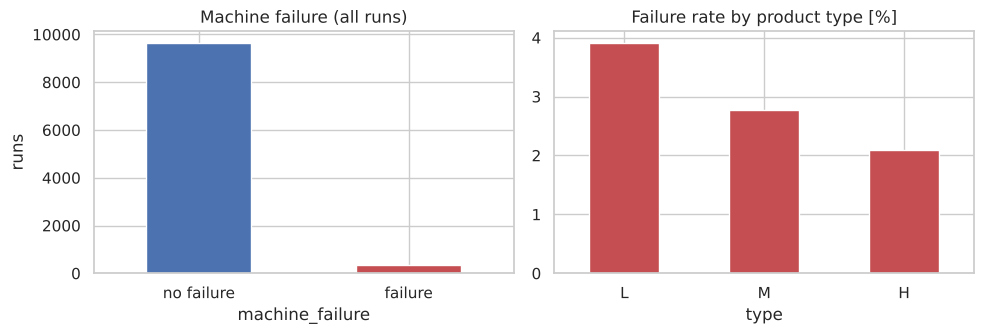

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df[D.TARGET].map({0: "no failure", 1: "failure"}).value_counts().plot.bar(ax=axes[0], color=["#4c72b0", "#c44e52"])
axes[0].set_title("Machine failure (all runs)")
axes[0].set_ylabel("runs")
axes[0].tick_params(axis="x", rotation=0)
(by_type.loc[["L", "M", "H"], "failure_rate"] * 100).plot.bar(ax=axes[1], color="#c44e52")
axes[1].set_title("Failure rate by product type [%]")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
E.save_figure(fig, FIG / "class_balance.png")

### Outliers

Box plots per class show whether extreme values exist and how they relate to
failures. Values here are physically plausible, so nothing is removed:
extremes of torque and speed are exactly where power failures happen.

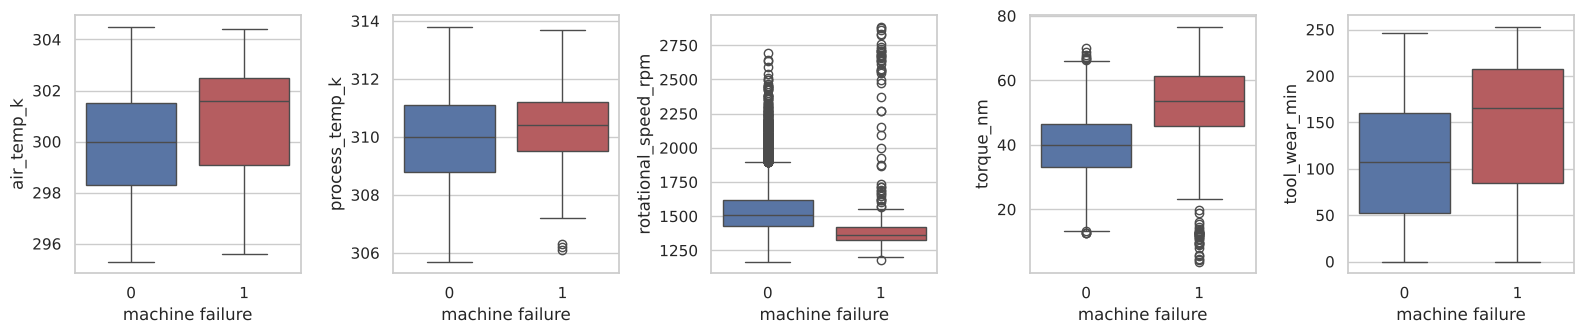

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, col in zip(axes, D.NUMERIC_FEATURES):
    sns.boxplot(data=df, x=D.TARGET, y=col, ax=ax, hue=D.TARGET, palette=["#4c72b0", "#c44e52"], legend=False)
    ax.set_xlabel("machine failure")
fig.tight_layout()
E.save_figure(fig, FIG / "boxplots_by_class.png")

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())

pd.DataFrame({
    "min": df[D.NUMERIC_FEATURES].min(),
    "max": df[D.NUMERIC_FEATURES].max(),
    "iqr_outliers": df[D.NUMERIC_FEATURES].apply(iqr_outliers),
})

,min,max,iqr_outliers
air_temp_k,295.3,304.5,0
process_temp_k,305.7,313.8,0
rotational_speed_rpm,1168.0,2886.0,418
torque_nm,3.8,76.6,69
tool_wear_min,0.0,253.0,0


### Label consistency

The label is defined by five failure modes. The UCI description gives the rules
for HDF, PWF and OSF; below we recompute them from the inputs and compare the
label and the flags with the description.

In [9]:
consistency = D.label_consistency(df)
summary = pd.DataFrame({
    "flags": consistency["flag_counts"],
    "flags with failure": consistency["flag_counts_with_failure"],
    "UCI description": {"twf": 120, "hdf": 115, "pwf": 95, "osf": 98, "rnf": 5},
})
display(summary)
print("Rule reproduces flag (rows out of 10000):", consistency["rule_agreement"])
print("Failures explained by HDF/PWF/OSF rules:", consistency["failures_explained_by_rules"],
      f"({consistency['failures_explained_by_rules'] / quality['failures']:.1%})")
print("Remaining failures:", consistency["failures_not_explained_by_rules"],
      "- with TWF flag:", consistency["unexplained_with_twf"],
      "- without any flag:", consistency["unexplained_without_any_flag"])
print("Tool wear at TWF flag:", consistency["tool_wear_range_at_twf"], "(UCI: 200-240 min)")
print("Flags without failure:", consistency["flags_without_failure"],
      "- of which RNF:", consistency["rnf_without_failure"])

,flags,flags with failure,UCI description
twf,46,46,120
hdf,115,115,115
pwf,95,95,95
osf,98,98,98
rnf,19,1,5


Rule reproduces flag (rows out of 10000): {'hdf': 10000, 'pwf': 10000, 'osf': 10000}
Failures explained by HDF/PWF/OSF rules: 287 (84.7%)
Remaining failures: 52 - with TWF flag: 43 - without any flag: 9
Tool wear at TWF flag: (198, 253) (UCI: 200-240 min)
Flags without failure: 18 - of which RNF: 18


Findings:

* the HDF, PWF and OSF rules from the UCI description reproduce the flags in
  all 10 000 rows - these failures are a deterministic function of the inputs;
* TWF: the file has 46 flags (UCI says 120 cases including 51 failures) and the
  tool wear at the flag spans 198-253 min, wider than the published 200-240;
* RNF: 19 flags instead of 5, and only one of them coincides with a failure;
* 9 failures have no flag at all, and 18 RNF flags have no failure.

**Decision:** `Machine failure` stays the label unchanged - it is the target we
are asked to predict, and correcting it would mean inventing data. The
discrepancies go to the limitations section; the 9 unflagged failures are
tracked in the error analysis as cases that no rule explains.

### Train/test split - before any fitting

The stratified 80/20 split (`random_state=42`) is the first operation after
the quality checks. Everything below - EDA, scaling, encoding, derived
features, model and threshold selection - uses the training set only. The test
set is used once, in chapter 7.

In [10]:
train_df, test_df = D.split_train_test(df)
X_train, y_train = D.features_and_target(train_df)
X_test, y_test = D.features_and_target(test_df)
pd.DataFrame({
    "rows": [len(train_df), len(test_df)],
    "failures": [int(y_train.sum()), int(y_test.sum())],
    "failure_rate": [y_train.mean(), y_test.mean()],
}, index=["train", "test"])

,rows,failures,failure_rate
train,8000,271,0.034
test,2000,68,0.034


## 4. Exploratory analysis (training set)

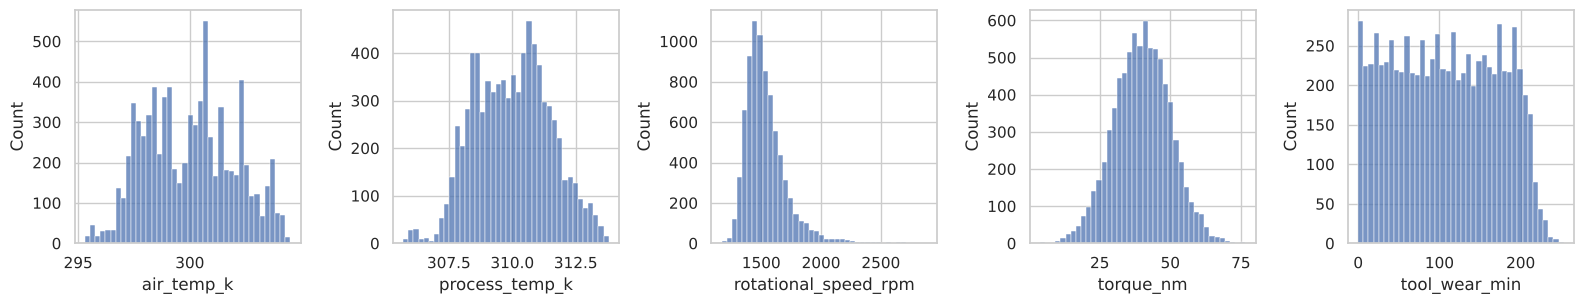

In [11]:
eda = train_df.assign(failure=train_df[D.TARGET].map({0: "no failure", 1: "failure"}))
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, col in zip(axes, D.NUMERIC_FEATURES):
    sns.histplot(eda[col], bins=40, ax=ax, color="#4c72b0")
fig.tight_layout()
E.save_figure(fig, FIG / "histograms.png")

Rotational speed versus torque, coloured by failure. Power is torque times
angular speed, so lines of constant power are hyperbolas; the dashed curves are
the 3500 W and 9000 W limits of the PWF rule.

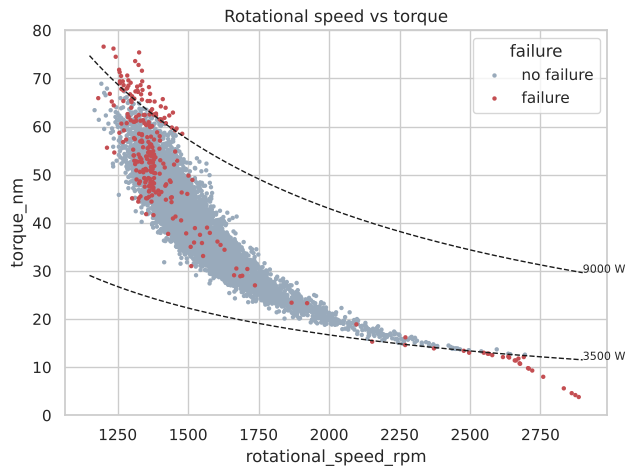

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=eda.sort_values(D.TARGET), x="rotational_speed_rpm", y="torque_nm", hue="failure",
                palette={"no failure": "#9ab", "failure": "#c44e52"}, s=10, linewidth=0, ax=ax)
rpm = np.linspace(1150, 2900, 200)
for power in (D.PWF_POWER_MIN_W, D.PWF_POWER_MAX_W):
    ax.plot(rpm, power / (rpm * 2 * np.pi / 60), "k--", lw=1)
    ax.annotate(f"{power} W", (rpm[-1], power / (rpm[-1] * 2 * np.pi / 60)), fontsize=8)
ax.set_ylim(0, 80)
ax.set_title("Rotational speed vs torque")
E.save_figure(fig, FIG / "speed_vs_torque.png")

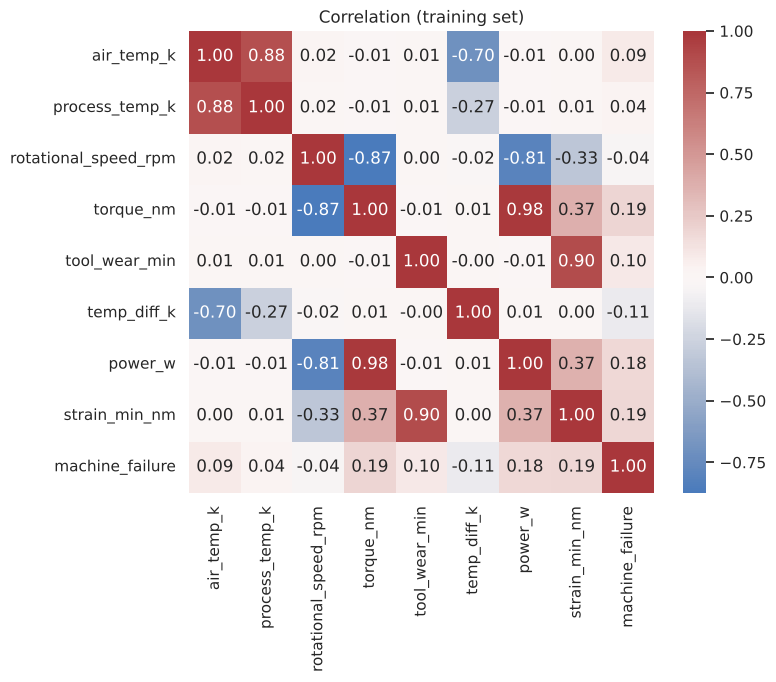

In [13]:
corr_frame = pd.concat([X_train[D.NUMERIC_FEATURES], compute_derived(X_train), y_train], axis=1)
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_frame.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation (training set)")
E.save_figure(fig, FIG / "correlation.png")

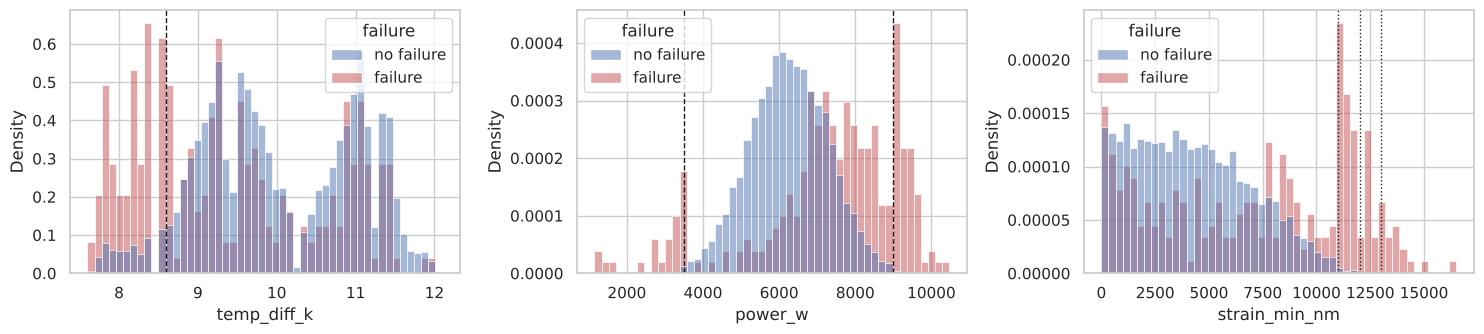

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
derived = compute_derived(X_train).assign(failure=eda["failure"])
for ax, col in zip(axes, ["temp_diff_k", "power_w", "strain_min_nm"]):
    sns.histplot(data=derived, x=col, hue="failure", bins=50, stat="density", common_norm=False, ax=ax,
                 palette={"no failure": "#4c72b0", "failure": "#c44e52"})
axes[0].axvline(D.HDF_TEMP_DIFF_K, color="k", ls="--", lw=1)
for p in (D.PWF_POWER_MIN_W, D.PWF_POWER_MAX_W):
    axes[1].axvline(p, color="k", ls="--", lw=1)
for limit in D.OSF_STRAIN_LIMITS.values():
    axes[2].axvline(limit, color="k", ls=":", lw=1)
fig.tight_layout()
E.save_figure(fig, FIG / "derived_features.png")

**Observations (training set):**

1. Failures are rare (3.4%) and concentrated at the extremes: high torque with
   low speed, low torque, and high tool wear. The speed-torque plot shows the
   failures sitting outside the 3500-9000 W power band.
2. Derived features separate the classes much better than the raw columns:
   failures pile up below a temperature difference of 8.6 K, outside the power
   band and above the strain limits. This is the first hint that the physics
   feature set will help.
3. Air and process temperature are strongly correlated (about 0.88), so they
   are largely redundant; their difference carries the useful signal. Torque
   and rotational speed are strongly negatively correlated (about -0.87), which
   is why power is a natural combination of the two.

**Limitations of the data:**

1. The data are synthetic and failures follow simple published rules - real
   machines degrade gradually and their failure mechanisms are not known in
   advance.
2. Every run is independent: there is no time series of sensor readings, so
   trends before a failure cannot be used. Part of the label (TWF, RNF and the
   unflagged failures) is random with respect to the inputs.

## 5. Models

Two feature sets:

* **raw** - `type` and the five measured parameters;
* **physics** - raw plus `temp_diff_k = process - air temperature`,
  `power_w = torque * rpm * 2*pi/60` and `strain_min_nm = tool wear * torque`.

Derived features are computed by a `FunctionTransformer` inside the Pipeline,
only from values known at prediction time. This is domain knowledge (heat
dissipation margin, mechanical power, tool load), not leakage: the failure-mode
flags are never used.

Every model is evaluated on both feature sets with the same
`StratifiedKFold(5, shuffle=True, random_state=42)` folds. Small grids are
tuned by `GridSearchCV` with PR-AUC (average precision). Recall, precision and
F1 in this table use the default 0.5 threshold; the cost-based threshold
follows in chapter 6.

In [15]:
cv_table, best = T.compare_models(train_df)
metrics = ["pr_auc", "roc_auc", "recall", "precision", "f1", "accuracy"]
cv_view = cv_table[["label", "feature_set", "best_params"]].copy()
for m in metrics:
    cv_view[m] = cv_table[f"{m}_mean"].map("{:.3f}".format) + " +/- " + cv_table[f"{m}_std"].map("{:.3f}".format)
cv_view

,label,feature_set,best_params,pr_auc,roc_auc,recall,precision,f1,accuracy
0,Hist gradient boosting,physics,"{""learning_rate"": 0.05, ""max_depth"": 3}",0.898 +/- 0.024,0.983 +/- 0.012,0.804 +/- 0.035,0.928 +/- 0.031,0.861 +/- 0.029,0.991 +/- 0.002
1,Random forest,physics,{},0.892 +/- 0.025,0.975 +/- 0.014,0.749 +/- 0.049,0.981 +/- 0.010,0.848 +/- 0.033,0.991 +/- 0.002
2,Hist gradient boosting,raw,"{""learning_rate"": 0.05, ""max_depth"": null}",0.812 +/- 0.040,0.973 +/- 0.017,0.672 +/- 0.059,0.840 +/- 0.058,0.744 +/- 0.038,0.984 +/- 0.002
3,Decision tree,physics,"{""max_depth"": 5}",0.792 +/- 0.038,0.940 +/- 0.016,0.923 +/- 0.027,0.410 +/- 0.016,0.568 +/- 0.016,0.952 +/- 0.003
4,Random forest,raw,{},0.760 +/- 0.033,0.969 +/- 0.013,0.391 +/- 0.046,0.936 +/- 0.048,0.549 +/- 0.040,0.978 +/- 0.001
5,Decision tree,raw,"{""max_depth"": 8}",0.572 +/- 0.065,0.849 +/- 0.044,0.712 +/- 0.075,0.361 +/- 0.041,0.476 +/- 0.037,0.947 +/- 0.008
6,Logistic regression,physics,"{""C"": 0.1}",0.486 +/- 0.026,0.916 +/- 0.014,0.838 +/- 0.046,0.159 +/- 0.008,0.267 +/- 0.013,0.844 +/- 0.009
7,Logistic regression,raw,"{""C"": 0.1}",0.446 +/- 0.025,0.897 +/- 0.016,0.804 +/- 0.067,0.137 +/- 0.005,0.234 +/- 0.010,0.822 +/- 0.007
8,Dummy (most frequent),physics,{},0.034 +/- 0.000,0.500 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.966 +/- 0.000
9,Dummy (most frequent),raw,{},0.034 +/- 0.000,0.500 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.966 +/- 0.000


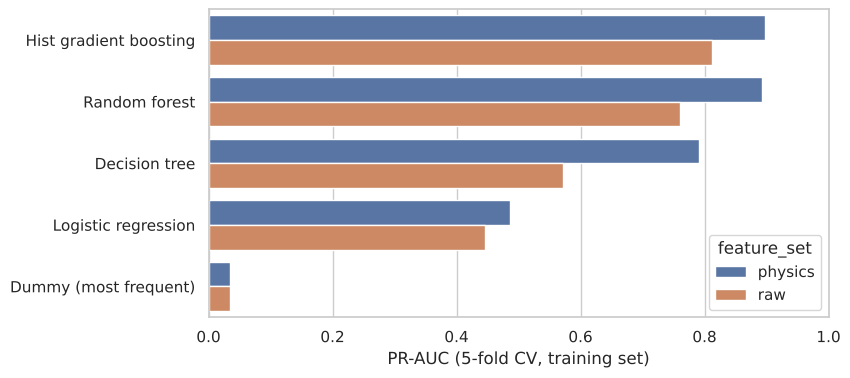

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_data = cv_table.assign(name=cv_table["label"])
sns.barplot(data=plot_data, y="name", x="pr_auc_mean", hue="feature_set", ax=ax)
ax.set_xlabel("PR-AUC (5-fold CV, training set)")
ax.set_ylabel("")
ax.set_xlim(0, 1)
E.save_figure(fig, FIG / "cv_pr_auc.png")

**Reading the table:**

* The baseline that always says "no failure" has 96.6% accuracy and PR-AUC
  0.034 (the failure rate). Accuracy cannot tell useful models from useless
  ones here, so it is reported only to show this trap.
* The physics feature set improves every model, most strongly the trees and
  ensembles: the decision tree goes from PR-AUC 0.57 to 0.79, the random forest
  from 0.76 to 0.89.
* Gradient boosting and the random forest on physics features are the two
  strongest candidates (PR-AUC 0.898 and 0.892, difference well inside one
  standard deviation). Logistic regression is clearly weaker, because the
  failure regions are bands and thresholds, not a single linear boundary.
* ROC-AUC is high for almost everything (0.85-0.98) and hides the differences
  that PR-AUC shows - with a rare positive class the many true negatives make
  ROC-AUC look good.

## 6. Threshold and model choice

The threshold minimises the cost `10 * FN + 1 * FP` (a missed failure costs ten
times a false alarm - an assumption, checked below for 5:1 and 20:1).
`TunedThresholdClassifierCV` chooses it on training folds. To estimate how the
whole procedure (model + threshold tuning) performs, it is wrapped in an outer
cross-validation: each outer fold tunes the threshold on its own inner folds
and is scored on data it has not seen.

In [17]:
threshold_table = T.compare_thresholds(train_df, best)
th_view = threshold_table[["label", "feature_set"]].copy()
for m in ["threshold", "recall", "precision", "f1", "fp_per_1000", "cost_per_1000"]:
    th_view[m] = threshold_table[f"{m}_mean"].map("{:.3f}".format) + " +/- " + threshold_table[f"{m}_std"].map("{:.3f}".format)
th_view

,label,feature_set,threshold,recall,precision,f1,fp_per_1000,cost_per_1000
0,Random forest,physics,0.248 +/- 0.055,0.849 +/- 0.032,0.842 +/- 0.074,0.844 +/- 0.043,5.625 +/- 2.984,56.875 +/- 11.639
1,Hist gradient boosting,physics,0.147 +/- 0.044,0.856 +/- 0.045,0.757 +/- 0.100,0.798 +/- 0.051,10.250 +/- 6.245,59.000 +/- 11.948
2,Decision tree,physics,0.726 +/- 0.285,0.804 +/- 0.075,0.717 +/- 0.161,0.740 +/- 0.087,14.250 +/- 13.916,80.500 +/- 17.164
3,Hist gradient boosting,raw,0.062 +/- 0.029,0.860 +/- 0.032,0.466 +/- 0.067,0.601 +/- 0.061,34.750 +/- 9.895,82.250 +/- 15.505
4,Random forest,raw,0.154 +/- 0.019,0.819 +/- 0.022,0.535 +/- 0.068,0.645 +/- 0.049,24.875 +/- 6.142,86.125 +/- 9.515
5,Decision tree,raw,0.887 +/- 0.041,0.661 +/- 0.096,0.557 +/- 0.095,0.592 +/- 0.044,19.500 +/- 8.114,134.500 +/- 27.121
6,Logistic regression,physics,0.722 +/- 0.049,0.639 +/- 0.046,0.287 +/- 0.047,0.394 +/- 0.050,56.000 +/- 14.751,178.500 +/- 22.342
7,Logistic regression,raw,0.776 +/- 0.018,0.572 +/- 0.045,0.311 +/- 0.034,0.402 +/- 0.034,43.500 +/- 6.357,188.500 +/- 15.923


### Selection criteria

In [18]:
criteria = threshold_table.merge(cv_table[["model", "feature_set", "pr_auc_mean", "pr_auc_std"]],
                                 on=["model", "feature_set"])
criteria = criteria.assign(
    pr_auc=lambda t: t["pr_auc_mean"].map("{:.3f}".format) + " +/- " + t["pr_auc_std"].map("{:.3f}".format),
    recall_at_threshold=lambda t: t["recall_mean"].round(3),
    false_alarms_per_1000=lambda t: t["fp_per_1000_mean"].round(1),
    cost_per_1000=lambda t: t["cost_per_1000_mean"].map("{:.1f}".format) + " +/- " + t["cost_per_1000_std"].map("{:.1f}".format),
    threshold_stability=lambda t: t["threshold_std"].round(3),
    latency_ms_single_row=lambda t: t["latency_ms"].round(1),
)[["label", "feature_set", "pr_auc", "recall_at_threshold", "false_alarms_per_1000", "cost_per_1000",
   "threshold_stability", "interpretability", "latency_ms_single_row"]]
criteria

,label,feature_set,pr_auc,recall_at_threshold,false_alarms_per_1000,cost_per_1000,threshold_stability,interpretability,latency_ms_single_row
0,Random forest,physics,0.892 +/- 0.025,0.849,5.6,56.9 +/- 11.6,0.055,low (ensemble),72.1
1,Hist gradient boosting,physics,0.898 +/- 0.024,0.856,10.2,59.0 +/- 11.9,0.044,low (ensemble),4.7
2,Decision tree,physics,0.792 +/- 0.038,0.804,14.2,80.5 +/- 17.2,0.285,high (rules),3.6
3,Hist gradient boosting,raw,0.812 +/- 0.040,0.860,34.8,82.2 +/- 15.5,0.029,low (ensemble),3.9
4,Random forest,raw,0.760 +/- 0.033,0.819,24.9,86.1 +/- 9.5,0.019,low (ensemble),59.4
5,Decision tree,raw,0.572 +/- 0.065,0.661,19.5,134.5 +/- 27.1,0.041,high (rules),2.8
6,Logistic regression,physics,0.486 +/- 0.026,0.639,56.0,178.5 +/- 22.3,0.049,high (coefficients),4.9
7,Logistic regression,raw,0.446 +/- 0.025,0.572,43.5,188.5 +/- 15.9,0.018,high (coefficients),3.7


**Choice: random forest on physics features.** Reasons:

* PR-AUC is practically equal to gradient boosting (0.892 vs 0.898, the gap is
  a quarter of one standard deviation), so the main metric does not separate
  the two leaders.
* At the cost-based threshold the random forest has the lowest expected cost
  (56.9 vs 59.0 per 1000 runs) with the same recall (0.85 vs 0.86) and about
  half the false alarms (5.6 vs 10.2 per 1000 runs). Fewer false alarms
  matter for a maintenance team that must react to each alarm.
* Its outcomes are more stable between folds: the standard deviation of
  false alarms is 3.0 vs 6.2 and of precision 0.07 vs 0.10.
* The decision tree is the only interpretable model with acceptable quality,
  but its cost is 40% higher and its threshold is unstable between folds (std
  0.29). It is kept as the explanation model in chapter 8.
* The price is speed: about 60 ms per single prediction instead of 7 ms, which
  is irrelevant for an operator entering one run at a time.

Note on process: during development the training script was once run end to
end with gradient boosting as a placeholder choice, which printed its test
metrics before this comparison was finished. The choice above is based only on
the cross-validated table; it is reported here for honesty (see the report,
section on limitations).

In [19]:
print("Frozen choice:", T.MODEL_SPECS[T.SELECTED_MODEL]["label"], "/", T.SELECTED_FEATURE_SET)
model = T.fit_final(train_df, best)
print("Threshold chosen on training folds:", round(model.best_threshold_, 4))
print("Best params:", best[(T.SELECTED_MODEL, T.SELECTED_FEATURE_SET)].named_steps["clf"].get_params()["n_estimators"], "trees")

Frozen choice: Random forest / physics


Threshold chosen on training folds: 0.2915
Best params: 300 trees


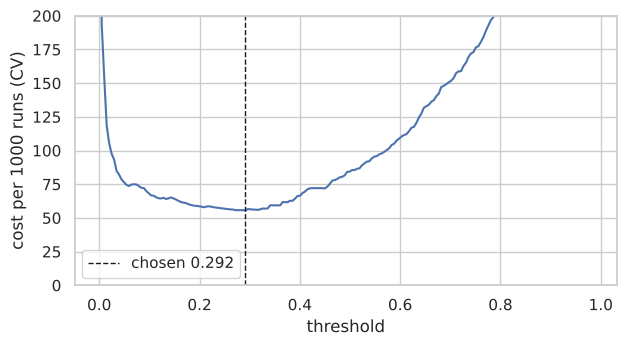

In [20]:
cv_curve = pd.DataFrame({"threshold": model.cv_results_["thresholds"], "cost_per_1000": -model.cv_results_["scores"]})
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cv_curve["threshold"], cv_curve["cost_per_1000"])
ax.axvline(model.best_threshold_, color="k", ls="--", lw=1, label=f"chosen {model.best_threshold_:.3f}")
ax.set_xlabel("threshold")
ax.set_ylabel("cost per 1000 runs (CV)")
ax.set_ylim(0, 200)
ax.legend()
E.save_figure(fig, FIG / "threshold_cost_curve.png")

### Sensitivity to the cost ratio (training folds)

In [21]:
sensitivity, sensitivity_models = T.cost_sensitivity(train_df, best)
sensitivity

,cost_ratio,threshold,cv_cost_per_1000
0,5:1,0.316,29.111
1,10:1,0.292,55.611
2,20:1,0.054,106.300


The threshold barely moves between 5:1 and 10:1 (0.32 vs 0.29), so the
decision rule is robust to that part of the assumption. At 20:1 a missed
failure becomes expensive enough that the threshold drops to about 0.05: the
model then raises many more alarms to catch the last, hardest failures. The
choice of the cost ratio is therefore a business decision that changes the
behaviour of the system and should be confirmed with the maintenance team.

## 7. Test set - used once

The model, feature set and threshold are frozen above. The next cell is the
only place where the test labels are used for evaluation. It compares the
chosen model with the baseline that always predicts "no failure".

In [22]:
# ===== SINGLE USE OF THE TEST SET =====
proba_test = model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= model.best_threshold_).astype(int)
test_metrics = E.metrics_at_threshold(y_test, proba_test, model.best_threshold_)
dummy = best[("dummy", "physics")]
dummy_proba = dummy.predict_proba(X_test)[:, 1]
dummy_metrics = E.metrics_at_threshold(y_test, dummy_proba, 0.5)
comparison = pd.DataFrame({"chosen model": test_metrics, "always 'no failure'": dummy_metrics}).T
comparison[["threshold", "pr_auc", "roc_auc", "recall", "precision", "f1", "accuracy", "tp", "fn", "fp", "tn", "fp_per_1000", "cost_per_1000"]]

,threshold,pr_auc,roc_auc,recall,precision,f1,accuracy,tp,fn,fp,tn,fp_per_1000,cost_per_1000
chosen model,0.292,0.871,0.97,0.824,0.918,0.868,0.992,56.0,12.0,5.0,1927.0,2.5,62.5
always 'no failure',0.500,0.034,0.50,0.000,0.000,0.000,0.966,0.0,68.0,0.0,1932.0,0.0,340.0


              precision    recall  f1-score   support

  no failure      0.994     0.997     0.996      1932
     failure      0.918     0.824     0.868        68

    accuracy                          0.992      2000
   macro avg      0.956     0.910     0.932      2000
weighted avg      0.991     0.992     0.991      2000



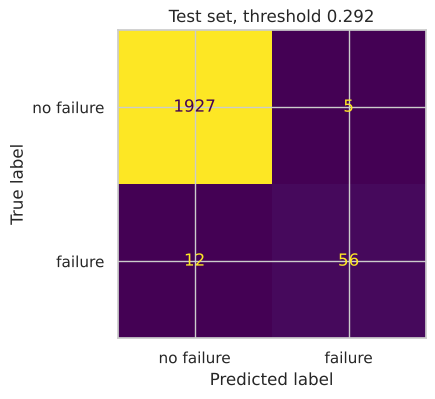

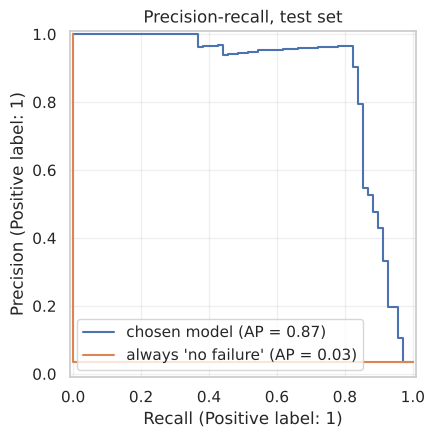

In [23]:
from sklearn.metrics import classification_report
print(classification_report(y_test, pred_test, target_names=["no failure", "failure"], digits=3))
fig = E.plot_confusion(y_test, pred_test, f"Test set, threshold {model.best_threshold_:.3f}")
E.save_figure(fig, FIG / "confusion_matrix_test.png")
fig = E.plot_pr_curves(y_test, {"chosen model": proba_test, "always 'no failure'": dummy_proba}, "Precision-recall, test set")
E.save_figure(fig, FIG / "pr_curve_test.png")

Cost of the decisions on the test set for each cost ratio (thresholds from the training folds above):

In [24]:
rows = []
for ratio, m in sensitivity_models.items():
    r = E.metrics_at_threshold(y_test, m.predict_proba(X_test)[:, 1], m.best_threshold_, fn_cost=ratio)
    rows.append({"cost_ratio": f"{ratio}:1", **{k: r[k] for k in ["threshold", "recall", "precision", "fn", "fp", "cost_per_1000"]}})
pd.DataFrame(rows)

,cost_ratio,threshold,recall,precision,fn,fp,cost_per_1000
0,5:1,0.316,0.824,0.918,12,5,32.5
1,10:1,0.292,0.824,0.918,12,5,62.5
2,20:1,0.054,0.912,0.392,6,96,108.0


**Test result.** On 2000 unseen runs the model finds 56 of 68 failures
(recall 0.824) with 5 false alarms (precision 0.918, 2.5 false alarms per 1000
runs). The cost is 62.5 per 1000 runs against 340 for the baseline that never
raises an alarm. Accuracy is 99.2% for the model and 96.6% for the baseline -
the 2.6-point difference hides a model that finds no failure at all.

The test PR-AUC (0.871) is slightly below the cross-validated estimate
(0.892 +/- 0.025) and the cost (62.5) is within one standard deviation of the
CV estimate (56.9 +/- 11.6), so the CV numbers were not overly optimistic.

With the 20:1 ratio the model would find 62 of 68 failures, but at the price
of 96 false alarms - this confirms the trade-off seen in the sensitivity
analysis.

### Error analysis

The failure-mode flags are used here only, after the fact, to see which kinds
of failure the model finds and which it misses.

In [25]:
cause_test = D.failure_cause(test_df)
breakdown = E.error_breakdown(y_test, pred_test, cause_test)
breakdown

,failures,detected,missed,recall
cause,,,,
HDF,29,28,1,0.966
PWF,12,12,0,1.000
OSF,16,16,0,1.000
TWF,9,0,9,0.000
no flag,2,0,2,0.000
all failures,68,56,12,0.824


In [26]:
explainable = cause_test.isin(["HDF", "PWF", "OSF"]).sum()
print(f"Test failures explained by the deterministic rules: {explainable} of {int(y_test.sum())} "
      f"({explainable / y_test.sum():.1%}) - the realistic ceiling for recall")
print(f"Model recall: {test_metrics['recall']:.3f}")
print(f"Recall on HDF/PWF/OSF failures: {pred_test[cause_test.isin(['HDF', 'PWF', 'OSF']).values].mean():.3f}")

Test failures explained by the deterministic rules: 57 of 68 (83.8%) - the realistic ceiling for recall
Model recall: 0.824
Recall on HDF/PWF/OSF failures: 0.982


In [27]:
errors = test_df.assign(probability=proba_test, prediction=pred_test, cause=cause_test)
errors = pd.concat([errors, compute_derived(errors)], axis=1)
errors = errors[errors["prediction"] != errors[D.TARGET]]
errors["error"] = np.where(errors[D.TARGET] == 1, "FN", "FP")
cols = ["udi", "error", "cause", "type", "air_temp_k", "process_temp_k", "rotational_speed_rpm", "torque_nm",
        "tool_wear_min", "temp_diff_k", "power_w", "strain_min_nm", "rnf", "probability"]
print("Errors:", errors["error"].value_counts().to_dict())
examples = pd.concat([
    errors[errors["error"] == "FN"].sort_values("probability", ascending=False).head(5),
    errors[errors["error"] == "FP"].sort_values("probability", ascending=False).head(5),
])
examples[cols].round(2)

Errors: {'FN': 12, 'FP': 5}


,udi,error,cause,type,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,temp_diff_k,power_w,strain_min_nm,rnf,probability
2864,2865,FN,TWF,H,300.6,309.4,1380,47.6,246,8.8,6878.83,11709.6,0,0.26
4778,4779,FN,HDF,H,303.6,312.2,1371,54.6,112,8.6,7838.96,6115.2,0,0.20
3695,3696,FN,TWF,L,302.2,311.3,1530,37.3,207,9.1,5976.25,7721.1,0,0.11
7087,7088,FN,TWF,L,300.6,310.3,1648,30.5,217,9.7,5263.63,6618.5,0,0.10
4034,4035,FN,TWF,L,302.0,310.8,1615,29.0,235,8.8,4904.55,6815.0,0,0.09
3794,3795,FP,none,M,302.2,310.8,1356,48.3,36,8.6,6858.60,1738.8,0,0.82
4231,4232,FP,none,L,302.2,310.8,1340,47.8,54,8.6,6707.51,2581.2,0,0.77
6612,6613,FP,none,L,301.6,310.6,1222,70.0,62,9.0,8957.73,4340.0,0,0.36
7677,7678,FP,none,L,300.6,311.7,1428,52.6,208,11.1,7865.79,10940.8,0,0.35
5988,5989,FP,none,H,300.7,310.8,1296,58.2,204,10.1,7898.72,11872.8,0,0.35


**Comment on the errors:**

* **HDF, PWF and OSF** - failures produced by deterministic rules - are found
  almost completely (56 of 57, recall 0.98). The single missed HDF case (UDI
  4779) has a temperature difference of exactly 8.6 K at the edge of the rule
  and a probability of 0.20, just below the threshold.
* **TWF** - 9 of 9 missed. Tool wear failures happen at a random moment in the
  200-240 min window, so the inputs say only "the tool is old", not "the tool
  breaks now". Raising alarms for every old tool would cost many false alarms.
* **No flag** - 2 failures that no rule explains; nothing in the inputs points
  to them (probabilities 0.00 and 0.04).
* **False alarms** - all 5 sit right at a rule boundary: two runs with a
  temperature difference of 8.6 K at speeds below 1380 rpm (UDI 4232 and 3795,
  the HDF edge), one with strain 10 941 minNm just below the 11 000 limit for
  type L (UDI 7678), one with power 8958 W close to 9000 W (UDI 6613) and one
  type H run with high wear and strain (UDI 5989). These are near misses,
  which is exactly where a maintenance engineer would want a second look.

The share of test failures explained by the deterministic rules (83.8%) is a
realistic ceiling for recall from these inputs; the model reaches 82.4%. The
remaining error - TWF, RNF and unflagged failures - is irreducible with these
data, not a modelling failure.

## 8. Explainability

### Permutation importance (test set, PR-AUC)

The pipeline takes the six raw inputs, so permutation is done on those; derived
features are recomputed from the permuted inputs. Importance is the drop in
PR-AUC when a column is shuffled.

,mean,std
torque_nm,0.654,0.021
rotational_speed_rpm,0.527,0.023
air_temp_k,0.455,0.049
tool_wear_min,0.321,0.037
process_temp_k,0.218,0.045
type,0.030,0.018


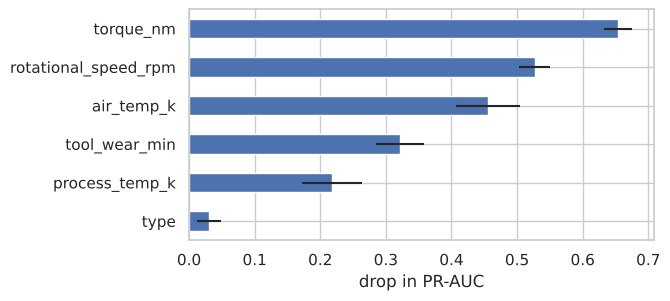

In [28]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(model, X_test, y_test, scoring="average_precision", n_repeats=10,
                              random_state=D.RANDOM_STATE, n_jobs=1)
importance = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                          index=X_test.columns).sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(6, 3))
importance["mean"].plot.barh(xerr=importance["std"], ax=ax, color="#4c72b0")
ax.invert_yaxis()
ax.set_xlabel("drop in PR-AUC")
E.save_figure(fig, FIG / "permutation_importance.png")
importance

### What did the decision tree learn?

The decision tree on physics features (depth from the grid) is fitted on the
training set without access to the rules. Its split thresholds are compared
with the rules from the UCI description.

In [29]:
tree_pipe = best[("tree", "physics")]
tree = tree_pipe.named_steps["clf"]
names = list(tree_pipe[:-1].get_feature_names_out())
print(E.tree_rules_text(tree, names))

|--- rotational_speed_rpm <= 1386.5
|   |--- temp_diff_k <= 8.7
|   |   |--- process_temp_k <= 312.1
|   |   |   |--- rotational_speed_rpm <= 1380.0
|   |   |   |   |--- temp_diff_k <= 8.6
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- temp_diff_k >  8.6
|   |   |   |   |   |--- class: 1
|   |   |   |--- rotational_speed_rpm >  1380.0
|   |   |   |   |--- power_w <= 8773.0
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- power_w >  8773.0
|   |   |   |   |   |--- class: 1
|   |   |--- process_temp_k >  312.1
|   |   |   |--- class: 0
|   |--- temp_diff_k >  8.7
|   |   |--- strain_min_nm <= 11013.6
|   |   |   |--- power_w <= 9005.2
|   |   |   |   |--- tool_wear_min <= 202.5
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- tool_wear_min >  202.5
|   |   |   |   |   |--- class: 1
|   |   |   |--- power_w >  9005.2
|   |   |   |   |--- class: 1
|   |   |--- strain_min_nm >  11013.6
|   |   |   |--- temp_diff_k <= 11.4
|   |   |   |   |--- process_temp_k <= 307.6
|   

In [30]:
splits = E.tree_thresholds(tree, names)
uci_rules = [
    ("HDF", "temp_diff_k", D.HDF_TEMP_DIFF_K),
    ("HDF", "rotational_speed_rpm", D.HDF_SPEED_RPM),
    ("PWF", "power_w", D.PWF_POWER_MIN_W),
    ("PWF", "power_w", D.PWF_POWER_MAX_W),
    ("OSF", "strain_min_nm", D.OSF_STRAIN_LIMITS["L"]),
    ("OSF", "strain_min_nm", D.OSF_STRAIN_LIMITS["M"]),
    ("OSF", "strain_min_nm", D.OSF_STRAIN_LIMITS["H"]),
]
rows = []
for mode, feature, value in uci_rules:
    candidates = splits.loc[splits["feature"] == feature, "threshold"]
    nearest = candidates.iloc[(candidates - value).abs().argmin()] if len(candidates) else np.nan
    rows.append({"mode": mode, "feature": feature, "UCI rule": value, "nearest tree split": round(nearest, 2),
                 "difference [%]": round(abs(nearest - value) / value * 100, 1) if len(candidates) else np.nan})
rule_comparison = pd.DataFrame(rows)
rule_comparison

,mode,feature,UCI rule,nearest tree split,difference [%]
0,HDF,temp_diff_k,8.6,8.55,0.6
1,HDF,rotational_speed_rpm,1380.0,1380.00,0.0
2,PWF,power_w,3500.0,3496.14,0.1
3,PWF,power_w,9000.0,8995.12,0.1
4,OSF,strain_min_nm,11000.0,11013.60,0.1
5,OSF,strain_min_nm,12000.0,11013.60,8.2
6,OSF,strain_min_nm,13000.0,11013.60,15.3


**The tree rediscovered the mechanism.** Without ever seeing the rules or the
failure-mode flags, the depth-5 tree split exactly at 1380 rpm and about 8.6 K
(HDF), at 3496 W and 8995 W (PWF: 3500 and 9000 W) and at 11 014 minNm (OSF,
the limit for type L, the most common variant). The higher OSF limits for types
M and H (12 000 and 13 000) are not found - at depth 5 the tree spends its
splits on the larger groups of failures.

Permutation importance tells the same story for the random forest: torque and
rotational speed (which together give power and, with tool wear, strain) are
the most important inputs, then air temperature (through the temperature
difference) and tool wear. The product type matters least - it only shifts the
overstrain limit.

## 9. Reproducibility check

`python -m ml.train` runs the same functions and saves `models/model.joblib`
with `models/model_card.json`. The saved card must agree with what this
notebook computed.

In [31]:
card = json.loads((ROOT / "models" / "model_card.json").read_text())
check = pd.DataFrame({
    "notebook": [model.best_threshold_, test_metrics["pr_auc"], test_metrics["recall"], test_metrics["fp"]],
    "model card": [card["threshold"], card["test_metrics"]["pr_auc"], card["test_metrics"]["recall"], card["test_metrics"]["fp"]],
}, index=["threshold", "test PR-AUC", "test recall", "test FP"])
display(check)
assert np.allclose(check["notebook"], check["model card"]), "notebook and saved model disagree"
print("model_id:", card["model_id"], "| sklearn", card["sklearn_version"], "| trained", card["trained_at"])

,notebook,model card
threshold,0.292,0.292
test PR-AUC,0.871,0.871
test recall,0.824,0.824
test FP,5.000,5.000


model_id: 5322a5e0907f | sklearn 1.9.1 | trained 2026-11-04T23:29:52+00:00


In [32]:
results = {
    "quality": quality,
    "consistency": {k: v for k, v in consistency.items() if k != "tool_wear_range_at_twf"},
    "cv_table": cv_table.drop(columns=["label"]).to_dict(orient="records"),
    "threshold_table": threshold_table.drop(columns=["label"]).to_dict(orient="records"),
    "sensitivity": sensitivity.to_dict(orient="records"),
    "test_metrics": test_metrics,
    "dummy_test_metrics": dummy_metrics,
    "error_breakdown": breakdown.reset_index().to_dict(orient="records"),
    "rule_comparison": rule_comparison.to_dict(orient="records"),
    "permutation_importance": importance["mean"].to_dict(),
}
(ROOT / "reports" / "results.json").write_text(json.dumps(results, indent=2, default=float) + "\n")
print("Saved reports/results.json")

Saved reports/results.json
